<a href="https://colab.research.google.com/github/rabicenkonikita3-cloud/python-practice-algos/blob/student/636-01/hw_7_rabichenko_28_10..ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Точность до 0.9707602339181286

Признаков после PCA 10

Точность после PCA 0.9590643274853801

Разница 0.011695906432748537


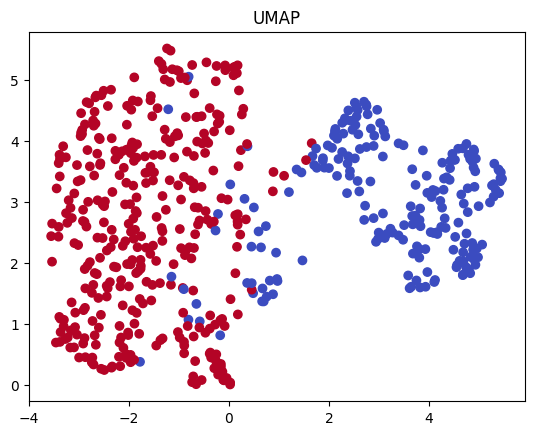

In [8]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3, random_state=42)

clf1=RandomForestClassifier(random_state=42).fit(X_train, y_train)
acc1 =accuracy_score(y_test,clf1.predict(X_test))
scaler=StandardScaler()
X_tr_s = scaler.fit_transform(X_train)
X_te_s = scaler.transform(X_test)

pca=PCA(n_components=0.95, random_state=42)
X_tr_p =pca.fit_transform(X_tr_s)
X_te_p = pca.transform(X_te_s)

clf2 = RandomForestClassifier(random_state=42).fit(X_tr_p, y_train)
acc2 = accuracy_score(y_test,clf2.predict(X_te_p))
X_s = scaler.fit_transform(X)
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X_s)

print("Точность до", acc1)
print()
print("Признаков после PCA",pca.n_components_)
print()
print("Точность после PCA", acc2)
print()
print("Разница",acc1 - acc2)

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap="coolwarm")
plt.title("UMAP")
plt.show()

